# Solving the two orders

<div class="alert alert-info">

**Summary**

In this lesson the reader builds both orders of the portfolio–consumption model from their files, supplies the value after the last period, solves each order with a method chosen for each stage, recovers one order's value from the other's, and changes the method of one stage. The objects inspected are the consumption rule, the risky share and the check behind each claim. This lesson solves.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [Two stages, two orders](01-two-stages-two-orders.ipynb) and [A trellis built backwards](02-a-life-cycle-built-backwards.ipynb): the two orders and their trellis files.

**Formal account** — [Periods](../../../docs/Bellman-Sym/06-period.md) and [Trellises](../../../docs/Bellman-Sym/07-trellis.md): the period written once, and the trellis indexed back from its last period.

**See also** — [The portfolio–consumption application](../../../applications/cons-port/README.md): the tool and its acceptance test.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[handler]] | The function of an application's tool that carries a method out. |
| [[trellis]] | A model's sequence of periods, built backwards from the last. |
| [[specified_stage\|specified]] | Said of a stage bound to its values, methods and settings. |

</div>

A household lives six years. Each year it consumes $\mathrm{c}$ out of its resources $\mathrm{m}$, with utility $u(\mathrm{c}) = \mathrm{c}^{1-\rho}/(1-\rho)$ and discount factor $\beta$, and invests its savings, the share $\varsigma$ in a risky asset with gross return $\Psi$ and the rest at the safe gross return $R$; the return and transitory income $\theta$ are drawn after the share is chosen. The periods of the model's [[trellis]] hold the portfolio [[stage]] first or consumption first, and the two orders differ in where the year ends. Write $V_h$ for the value at the portfolio decision, a function of capital $\mathrm{k}$, and $W_h$ for the value at the consumption decision, a function of resources, in the year $h$ years before the last, $h = 0, \dots, 5$.

Portfolio first, the year begins with the portfolio choice and ends on savings:

$$
V_h(\mathrm{k}) = \max_{\varsigma \in [0, 1]} \mathbb{E}\big[W_h\big(\mathrm{k}(\varsigma\Psi + (1 - \varsigma)R) + \theta\big)\big], \qquad
W_h(\mathrm{m}) = \max_{\mathrm{c} \in (0, \mathrm{m}]} u(\mathrm{c}) + \beta V_{h-1}(\mathrm{m} - \mathrm{c}),
$$

with $V_{-1}(\mathrm{a}) = u(\mathrm{a})$: the value after the last period is taken on savings.

Consumption first, the year boundary falls after the draw:

$$
W_h(\mathrm{m}) = \max_{\mathrm{c} \in (0, \mathrm{m}]} u(\mathrm{c}) + \beta V_h(\mathrm{m} - \mathrm{c}), \qquad
V_h(\mathrm{k}) = \max_{\varsigma \in [0, 1]} \mathbb{E}\big[W_{h-1}\big(\mathrm{k}(\varsigma\Psi + (1 - \varsigma)R) + \theta\big)\big],
$$

with $W_{-1}(\mathrm{m}) = u(\mathrm{m})$: the value after the last period is taken on next year's resources.

| Written | Meaning |
|---|---|
| `m`, `c` | resources $\mathrm{m}$ at the consumption decision, and consumption $\mathrm{c}$ |
| `k`, `ς` | capital $\mathrm{k}$ at the portfolio decision, and the risky share $\varsigma$ |
| `Ψ`, `β`, `ρ` | the risky gross return $\Psi$, the discount factor $\beta$, relative risk aversion $\rho$ |
| `h` | the period $h$ years before the last; $h = 0$ is the last |

The lesson reads these files, given by their paths from the repository root:

- `applications/cons-port/declaration/stages/cons/cons.bl`
- `applications/cons-port/declaration/stages/port/port.bl`
- `applications/cons-port/declaration/stages/disc/disc.bl`
- `applications/cons-port/declaration/spec.port-cons.yml`
- `applications/cons-port/declaration/trellis.port-cons.yml`
- `applications/cons-port/declaration/spec.cons-port.yml`
- `applications/cons-port/declaration/trellis.cons-port.yml`
- `applications/cons-port/declaration/trellis.port-cons-vfi.yml`
- `applications/cons-port/declaration/calibration/portfolio.yml`
- `applications/cons-port/declaration/stages/cons/methods.bl`
- `applications/cons-port/declaration/stages/port/methods.bl`
- `applications/cons-port/declaration/stages/disc/methods.bl`
- `applications/cons-port/declaration/stages/cons/methods.vfi.bl`
- `applications/cons-port/declaration/settings/cons_wide.yml`
- `applications/cons-port/declaration/settings/port_wide.yml`
- `applications/cons-port/declaration/settings/cons_vfi.yml`
- `applications/cons-port/code/cons_port_tool.py`

It writes no file. The first code cell imports the collection's set-up module, checkout, then NumPy, the functions the lesson calls from bellman.trellis, and the model's tool.

In [1]:
import checkout
import numpy as np
from bellman.trellis import (
    calibrate_trellis,
    changed_positions,
    configure_trellis,
    elaborate_trellis,
    load_recipe,
    load_trellis,
    methodize_trellis,
)
import cons_port_tool as tool

## A method for each stage

The package constructs the stages and binds their values, methods and settings; the model's numerical tool, `cons_port_tool.py`, solves, evaluating only equations the package compiles from the stage files and their additions. A methods file is an **addition**, a `.bl` file beside the stage file whose typing entries name, at a place of the stage, the method, its grid and its [[handler]], the tool's function that carries the method out, and whose lines append to the stage's blocks the lines of the method and the derivative of the value. The next cell prints the consumption stage's addition. The endogenous-grid method of Carroll (2006, "The method of endogenous gridpoints for solving dynamic stochastic optimization problems", *Economics Letters* 91(3)) is typed on the block `policy` by the entry `method : !egm` and stands on the policy builder; its handler is `cons-port:egm`, the function `egm`, which computes consumption from the Euler equation on the grid of savings the entry `grid : !Cartesian(a=(a_min, a_max, n_a, !expmult))` names, one factor for the savings coordinate whose bounds and count are the names of settings and whose spacing is the word `!expmult`. The block's three lines, the inverse Euler equation with its clause, the endogenous grid of resources and the identification of the policy, stand in the builder in place of the maximization. The block `cntn_to_dcsn` appends the envelope condition, the derivative of the decision value, and its header types the Evaluation that closes the decision builder with `!Linear` on the grid of resources, which stores the value and its derivative by their values on that grid and interpolates linearly between them.

In [2]:
print(open("applications/cons-port/declaration/stages/cons/methods.bl").read())

@methods: cons
# The methods of the consumption stage at the occurrences of the two recipes,
# spec.cons-port.yml and spec.port-cons.yml, whose settings file
# settings/cons_wide.yml values multi-exponential grids: the endogenous grid
# method on the policy builder, realized by the function egm of
# code/cons_port_tool.py on the savings grid, with its three lines, the inverse
# Euler equation, the endogenous grid of resources and the identification of
# the policy; the envelope line of the decision value; and one linear
# representation of that value and of its stated derivative on the grid of
# resources. The marginal utility and its inverse are defined in closed form,
# so that nothing is differentiated. The three lines of the policy block stand
# in place of the maximization at the operative level, and stage.declared keeps
# the maximization. Each grid is its own typing entry at its place, the word
# !expmult its spacing; methods.reference.bl writes the same methods on evenly
# spac

The portfolio stage's addition, which the next cell prints, types the policy builder with `!time_iteration`, the first-order condition of the share as the block's one line, with the handler `cons-port:share_search`, the function `share_search`, a search over evenly spaced shares in $[0, 1]$ for the largest expected value, as many shares as the grid `!Cartesian(ς=(Γ_ς, n_ς))` counts on the feasible set; Gauss–Hermite quadrature at the expectation `E_Ψ_θ` of each of its two blocks, `!gauss_hermite(n_Ψ=n_Ψ_nodes, n_θ=n_θ_nodes)`, one node count per shock, with the handler `cons-port:gauss_hermite`, the function `normal_nodes`; the envelope line of the decision value, appended to the block `cntn_to_dcsn`, whose header types the Evaluation with `!Linear` on the grid of capital, which stores the value and its derivative and interpolates linearly between its points; and `!monte_carlo` on the forward law, which the tool does not read.

In [3]:
print(open("applications/cons-port/declaration/stages/port/methods.bl").read())

@methods: port
# The methods of the portfolio stage at the occurrences of the two recipes and
# of trellis.port-cons-vfi.yml, whose settings file settings/port_wide.yml
# values a multi-exponential capital grid: time iteration on the policy
# builder with the first-order condition of the share as its line, realized by
# the function share_search of code/cons_port_tool.py, which compares n_ς
# shares on the feasible set at each point of the capital grid; Gauss-Hermite
# quadrature at every occurrence of the expectation; the envelope line of the
# decision value; the linear representation of the decision value and of its
# stated derivative on the capital grid; and the forward law drawn by Monte
# Carlo. The line euler stands in place of the maximization at the operative
# level, and stage.declared keeps the maximization. Each grid is its own
# typing entry at its place; methods.reference.bl writes the fixed reference's
# handlers on an evenly spaced grid.

n_k : ℕ              :: ["numb

The discount stage's addition names no handler and no grid: its two forward builders are deterministic, and the tool applies the stage's equations.

In [4]:
print(open("applications/cons-port/declaration/stages/disc/methods.bl").read())

@methods: disc
# The methods of the discount stage: its two forward builders are
# deterministic, a representation of a forward builder's measure without a
# grid. Its two value builders bind nothing.

arvl_to_dcsn.method : !deterministic
dcsn_to_cntn.method : !deterministic



## Build first

Both orders are built from their recipes as in [lesson 02](02-a-life-cycle-built-backwards.ipynb) and are not changed later; `_b` marks the portfolio-first order, whose returns are drawn at the beginning of the period, and `_e` the consumption-first order. The next cell reads the portfolio-first recipe.

In [5]:
syntactic_b = load_recipe("applications/cons-port/declaration", "spec.port-cons.yml")

The next cell constructs and binds it as `model_b`.

In [6]:
elaborated_b = elaborate_trellis(syntactic_b)
methodized_b = methodize_trellis(elaborated_b, syntactic_b)
calibrated_b = calibrate_trellis(methodized_b, syntactic_b)
model_b = configure_trellis(calibrated_b, syntactic_b)


The next cell reads the consumption-first recipe. Its trellis file repeats its period three times, so `model_e` holds the last three years, and the comparisons between the two orders below are made at $h = 2$, a year both models hold.

In [7]:
syntactic_e = load_recipe("applications/cons-port/declaration", "spec.cons-port.yml")

The next cell constructs and binds it as `model_e`.

In [8]:
elaborated_e = elaborate_trellis(syntactic_e)
methodized_e = methodize_trellis(elaborated_e, syntactic_e)
calibrated_e = calibrate_trellis(methodized_e, syntactic_e)
model_e = configure_trellis(calibrated_e, syntactic_e)


The first year of `model_b` holds three specified stages, and `model_e` joins its three years by `{w: m}`.

In [9]:
model_b["periods"][5]["stages"], model_e["inter_connectors"]

({'port': ElaboratedStage('port', specified),
  'cons': ElaboratedStage('cons', specified),
  'disc': ElaboratedStage('disc', specified)},
 [{'w': 'm'}, {'w': 'm'}])

The next cell prints the consumption stage's settings, each with the set its addition declares. Its grids are multi-exponential, dense near zero, where utility is steep, by the word `!expmult` of the grid entries, and extend to 2,000; the share search holds a draw of resources above 2,000 at 2,000, the end of its grid. The last two names are valued by the settings file and read by no method.

In [10]:
model_b["periods"][0]["stages"]["cons"].settings

name    set  value   read at                by       grid
n_a     ℕ    16000   policy                 !egm     !Cartesian
a_min   Xa   1e-06   policy                 !egm     !Cartesian
a_max   Xa   2000.0  policy                 !egm     !Cartesian
n_m     ℕ    64000   cntn_to_dcsn.evaluate  !Linear  !Cartesian
m_min   Xm   0.01    cntn_to_dcsn.evaluate  !Linear  !Cartesian
m_max   Xm   2000.0  cntn_to_dcsn.evaluate  !Linear  !Cartesian
n_toll       200
n_init       20041

The next cell prints the portfolio stage's settings: its grid of capital, seven quadrature nodes for each shock at each of the two expectations, 201 candidate shares, and the draws of the forward law.

In [11]:
model_b["periods"][0]["stages"]["port"].settings

name       set  value   read at                by               grid
n_k        ℕ    16000   cntn_to_dcsn.evaluate  !Linear          !Cartesian
k_min      ℝ₊   1e-06   cntn_to_dcsn.evaluate  !Linear          !Cartesian
k_max      ℝ₊   2000.0  cntn_to_dcsn.evaluate  !Linear          !Cartesian
n_ς        ℕ    201     policy                 !time_iteration  !Cartesian
n_Ψ_nodes  ℕ    7       cntn_to_dcsn.E_Ψ_θ     !gauss_hermite
n_Ψ_nodes  ℕ    7       policy.E_Ψ_θ           !gauss_hermite
n_θ_nodes  ℕ    7       cntn_to_dcsn.E_Ψ_θ     !gauss_hermite
n_θ_nodes  ℕ    7       policy.E_Ψ_θ           !gauss_hermite
n_sim      ℕ    10000   dcsn_to_cntn           !monte_carlo
sim_seed   ℕ    12345   dcsn_to_cntn           !monte_carlo

## The value after the last period

One explicit step supplies the value after the last period: the household consumes what it holds, so holding $x$ is worth $u(x)$, the line `V = 𝑢(c) + V[>]` of `cons.bl` at $\mathrm{c} = x$ and $V_\succ = 0$. One table serves both orders, on a multi-exponential grid with the size and upper end of the savings grid, `n_a` and `a_max`, so that it spans the savings grid and each savings point lies within `a_min` of one of its points. The next cell names the last consumption stage `ending`.

In [12]:
ending = model_b["periods"][0]["stages"]["cons"]

The tool's `terminal_value` evaluates that line on the grid, and with it the envelope line of the addition, `D_{m}V = 𝑑𝑢(c)`, the derivative of the value that the endogenous-grid method reads; the next cell names the table `terminal`. The grid's size and upper end are read from the stage by the names the settings file declares: `ending.settings["a_max"]` answers the record of one setting, and its `value` the number bound.

In [13]:
terminal = tool.terminal_value(ending, tool.expmult_grid(ending.settings["a_max"].value, ending.settings["n_a"].value))

Its 16,000 values fall without bound as $x$ goes to zero.

In [14]:
terminal

ValueFn(n=16000, range=[-1.235e+25, -6.25e-18])

The complete terminal mapping supplies the declared continuation value. `solve_period` checks it before constructing numerical records, grids, or operators. Each solved value retains unresolved callable conditions in `input_conditions`.


In [15]:
terminal_inputs = {"V[>]": terminal}
solved_0 = tool.solve_period(model_b["periods"][0], terminal_inputs)
solved_0["cons"].input_conditions


(Condition(condition='continuation-input', entries=(Identity(kind='field', stage='cons', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='cons', address=None, perch='cntn', field='a', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (a) in that order, and take values in ℝ.'),)

The period before it reads the portfolio stage's arrival value, to whose capital its connector `{a: k}` joins its savings; `continuation_across` finds it:

In [16]:
tool.continuation_across(model_b, 1, [solved_0]) is solved_0["port"]

True

`solve_trellis` repeats the step over every period. The next cell solves `model_b` by the endogenous-grid method and the share search (`egm`, `share_search` and `normal_nodes`, of `applications/cons-port/declaration/stages/cons/methods.bl` and `applications/cons-port/declaration/stages/port/methods.bl`) over its horizon of six periods, as `solved_b`: for each period, each stage's arrival value, a table of values, marginal values and the rule.

In [17]:
solved_b = tool.solve_trellis(model_b, terminal_inputs)

Six periods are solved, and the model is unchanged, its stages still specified.

In [18]:
len(solved_b), model_b["periods"][5]["stages"]["port"]

(6, ElaboratedStage('port', specified))

## The portfolio-first order

The figures read the consumption rules on resources up to 10, where they bend; the next cell marks those grid points.

In [19]:
up_to_10 = solved_b[0]["cons"].grid <= 10.0

The next cell draws the consumption rule at $h = 0$, 2 and 5, with the line $\mathrm{c} = \mathrm{m}$.

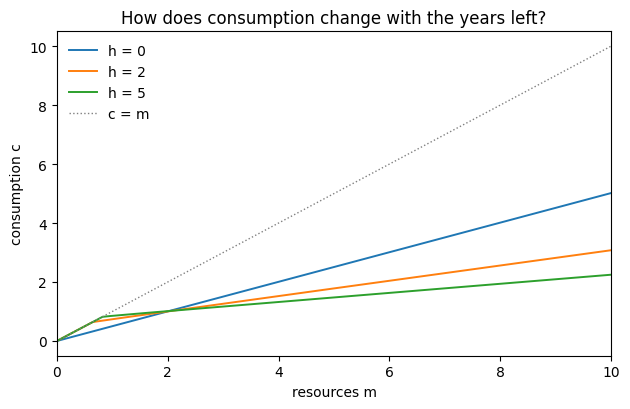

In [20]:
tool.plot_functions({"h = 0": (solved_b[0]["cons"].grid[up_to_10], solved_b[0]["cons"].policy["c"][up_to_10]),
                     "h = 2": (solved_b[2]["cons"].grid[up_to_10], solved_b[2]["cons"].policy["c"][up_to_10]),
                     "h = 5": (solved_b[5]["cons"].grid[up_to_10], solved_b[5]["cons"].policy["c"][up_to_10])},
                    xlabel="resources m", ylabel="consumption c", diagonal="c = m", xlim=(0, 10),
                    title="How does consumption change with the years left?")

With one year left the household does not consume everything, since the terminal step values its savings: it maximizes $u(\mathrm{c}) + \beta u(\mathrm{m} - \mathrm{c})$ and so consumes the share $1/(1 + \beta^{1/\rho})$ of its resources. With more years left the rule lies above the one-year rule at low resources and below it higher up; at $h = 2$ and 5 it lies on the line $\mathrm{c} = \mathrm{m}$ at the lowest resources shown, where the borrowing limit binds. The next cell computes that share from the stages' calibration and names it `share_0`.

In [21]:
share_0 = 1 / (1 + model_b["periods"][0]["stages"]["disc"].par["β"].value ** (1 / ending.par["ρ"].value))

The next cell marks resources from 1 to 10, where the rule is compared with it.

In [22]:
from_1_to_10 = (solved_b[0]["cons"].grid >= 1.0) & (solved_b[0]["cons"].grid <= 10.0)

The rule departs from the share only through interpolation of the terminal table. Read at the table's own points, the marginal value gives exactly the share. The consumption rule reads it at the points of the savings grid, each within `a_min` of a point of the table, by linear interpolation between points $\Delta$ apart at savings $\mathrm{a}$. To first order, that interpolation moves $\mathrm{c}/\mathrm{m}$ from the share by at most `a_min` times $\Delta(\rho + 1)/(8\mathrm{a}^2)$, which is below `a_min` because $\Delta < 8\mathrm{a}^2/(\rho + 1)$ at the savings that resources from 1 to 10 leave.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| $\mathrm{c}/\mathrm{m}$ at $h = 0$ and `share_0` | `deviation_0`, below | `a_min` | interpolation of the terminal table, to first order |

The next cell computes the largest deviation.

In [23]:
deviation_0 = float(np.max(np.abs(solved_b[0]["cons"].policy["c"][from_1_to_10] / solved_b[0]["cons"].grid[from_1_to_10] - share_0)))

The share, the deviation and the tolerance, which the assertion restates:

In [24]:
assert deviation_0 <= ending.settings["a_min"].value
share_0, deviation_0, ending.settings["a_min"].value

(0.5017009098771079, 7.798083290211366e-10, 1e-06)

The next cell draws the risky share at the same $h$, on capital up to 50.

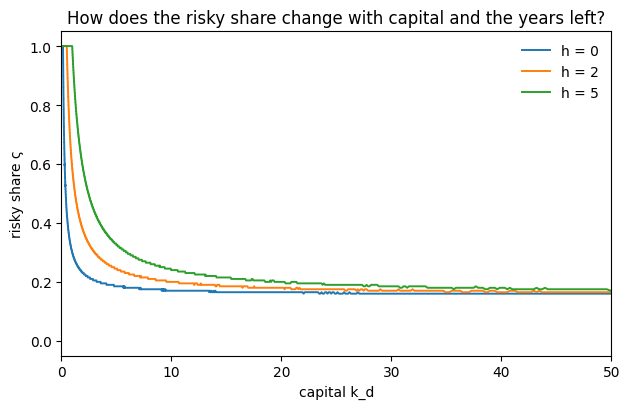

In [25]:
tool.plot_functions({"h = 0": (solved_b[0]["port"].grid, solved_b[0]["port"].policy["varsigma"]),
                     "h = 2": (solved_b[2]["port"].grid, solved_b[2]["port"].policy["varsigma"]),
                     "h = 5": (solved_b[5]["port"].grid, solved_b[5]["port"].policy["varsigma"])},
                    xlabel="capital k_d", ylabel="risky share ς", xlim=(0, 50),
                    title="How does the risky share change with capital and the years left?")

The share is highest at small capital, where next year's resources are mostly income, and falls as capital grows; more years of income left raise it.

## The consumption-first order

The next cell solves `model_e` from the same table by the endogenous-grid method and the share search (`egm`, `share_search` and `normal_nodes`, of `applications/cons-port/declaration/stages/cons/methods.bl` and `applications/cons-port/declaration/stages/port/methods.bl`) over its three periods, as `solved_e`.

In [26]:
solved_e = tool.solve_trellis(model_e, terminal_inputs)

The next cell draws consumption at $h = 2$ in both orders.

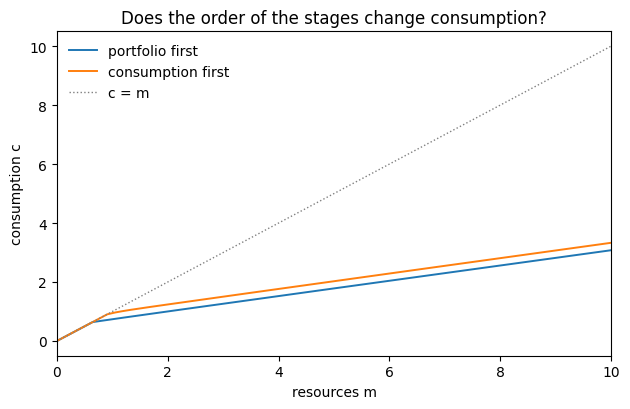

In [27]:
tool.plot_functions({"portfolio first": (solved_b[2]["cons"].grid[up_to_10], solved_b[2]["cons"].policy["c"][up_to_10]),
                     "consumption first": (solved_e[2]["cons"].grid[up_to_10], solved_e[2]["cons"].policy["c"][up_to_10])},
                    xlabel="resources m", ylabel="consumption c", diagonal="c = m", xlim=(0, 10),
                    title="Does the order of the stages change consumption?")

The rules differ because the orders end differently, not because consumption begins with other information: after the last consumption decision the portfolio-first order values the savings at once, and the consumption-first order invests them once more and receives one more draw of the return and of income, and the terminal value is taken on the resources those draws give.

The next cell draws the risky share at $h = 2$ in both orders.

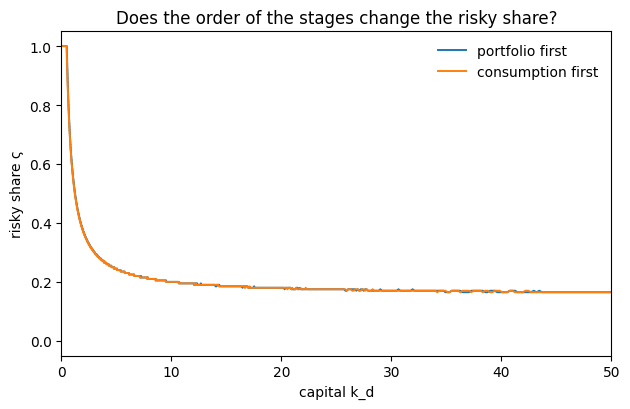

In [28]:
tool.plot_functions({"portfolio first": (solved_b[2]["port"].grid, solved_b[2]["port"].policy["varsigma"]),
                     "consumption first": (solved_e[2]["port"].grid, solved_e[2]["port"].policy["varsigma"])},
                    xlabel="capital k_d", ylabel="risky share ς", xlim=(0, 50),
                    title="Does the order of the stages change the risky share?")

The two shares nearly coincide at every level of capital shown. The orders differ in how the last year ends, so at $h = 2$ they solve different problems, and the comparison states how near the shares are rather than an identity: within ten candidate spacings of the share search, $10/(n_\varsigma - 1)$. Both orders store the share on the same grid of capital.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| the risky share at $h = 2$ on capital up to 50, portfolio first and consumption first | `share_gap`, below | $10/(n_\varsigma - 1)$ | the orders differ in the last year's ending; ten candidate spacings state what nearly means |

The next cell marks capital up to 50.

In [29]:
up_to_50 = solved_b[2]["port"].grid <= 50.0

The next cell computes the largest difference.

In [30]:
share_gap = float(np.max(np.abs(solved_b[2]["port"].policy["varsigma"][up_to_50] - solved_e[2]["port"].policy["varsigma"][up_to_50])))

The difference and the tolerance, which the assertion restates:

In [31]:
assert share_gap <= 10 / (model_b["periods"][0]["stages"]["port"].settings["n_ς"].value - 1)
share_gap, 10 / (model_b["periods"][0]["stages"]["port"].settings["n_ς"].value - 1)

(0.03500000000000003, 0.05)

## Numerical records

The supplied mapping is checked before the builder returns its detached numerical records. `grids` holds constructed finite grids, `grid_factors` holds bound data for grids placed by a handler, and `laws` holds selected probability laws. Numerical operators retain these records and no stage.

In [32]:
port_inputs = {"V[>]": solved_0["cons"]}
port_stage = model_b["periods"][0]["stages"]["port"]
port_conditions = port_stage.check_inputs(port_inputs)
port_record = port_stage.dcsn.builder.bwd.kernels(inputs=port_inputs)
port_conditions, port_record.grids, port_record.grid_factors, port_record.laws

((Condition(condition='continuation-input', entries=(Identity(kind='field', stage='port', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='port', address=None, perch='cntn', field='w', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (w) in that order, and take values in ℝ.'),),
 mappingproxy({'cntn_to_dcsn.evaluate': Refusal(reason="stage 'port', place 'cntn_to_dcsn.evaluate', grid !Cartesian(k=(k_min, k_max, n_k, !expmult)): its factor k=(k_min, k_max, n_k, !expmult) names the spacing word !expmult, whose nodes its handler places, and the core identifies no construction of them; numerical construction establishes the finite points of a grid and every property it requires before the grid is used, and supplies no default", diagnostic={'address': 'cntn_to_

## One order from the other

Write $P$, $D$ and $C$ for the operators of the portfolio, discount and consumption stages, each mapping the value a stage continues to into its arrival value. A portfolio-first period applies $D$, $C$, then $P$; a consumption-first period $P$, $D$, then $C$. Hence, on the three years `model_e` holds, $(P \circ C \circ D)^3 = P \circ (C \circ D \circ P)^2 \circ C \circ D$: for value functions the year boundary changes nothing. The tool's `stage_operator` gives a stage occurrence's operator; the next cell names the portfolio stage's `port_step`.

In [33]:
port_step = tool.stage_operator(model_b["periods"][0]["stages"]["port"], terminal_inputs)


The next cell gives the discount stage's operator, `disc_step`.

In [34]:
disc_step = tool.stage_operator(model_b["periods"][0]["stages"]["disc"], terminal_inputs)


The next cell gives the consumption stage's operator, `cons_step`.

In [35]:
cons_step = tool.stage_operator(model_b["periods"][0]["stages"]["cons"], terminal_inputs)


The next cell applies $C \circ D$ to the terminal table and solves from it the last two periods of `model_e`, $h = 0$ and 1, by the endogenous-grid method and the share search (`egm`, `share_search` and `normal_nodes`, of `applications/cons-port/declaration/stages/cons/methods.bl` and `applications/cons-port/declaration/stages/port/methods.bl`), as `two_e`.

In [36]:
two_e = tool.solve_trellis({"periods": model_e["periods"][:2], "inter_connectors": model_e["inter_connectors"][:1]},
                           {"V[>]": cons_step(disc_step(terminal))})


By the identity above, $P$ applied to `two_e` at $h = 1$ and the portfolio stage of `solved_b` at $h = 2$ are the same operators applied in the same sequence on the same grids, so the two agree exactly.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| $P$ applied to `two_e` at $h = 1$, and the portfolio stage of `solved_b` at $h = 2$ | `recovered`, below | 0 | the same operators in the same sequence on the same grids |

The next cell computes the largest difference.

In [37]:
recovered = float(np.max(np.abs(port_step(two_e[1]["cons"]).values - solved_b[2]["port"].values)))

It is zero, as the assertion restates.

In [38]:
assert recovered == 0.0
recovered

0.0

## One stage's method changed

`trellis.port-cons-vfi.yml` changes only the consumption stage's binding files: the replacing selection `methods.vfi.bl` beside the stage file, which the next cell prints, and the settings file `cons_vfi.yml`. The selection types the decision builder `cntn_to_dcsn` with `!vfi`, a grid search over candidate consumption levels, handler `cons-port:consumption_search`, the function `consumption_search`, with the number of candidates in its grid, and the Evaluation of that builder with `!Linear` on the grid of resources; it appends no line, so the policy builder keeps the maximization the stage file writes.

In [39]:
print(open("applications/cons-port/declaration/stages/cons/methods.vfi.bl").read())

@methods: cons
# The methods of the consumption stage at the occurrences of
# trellis.port-cons-vfi.yml, whose settings file settings/cons_vfi.yml values a
# multi-exponential grid of resources: value function iteration on the decision
# value builder, realized by the function consumption_search of
# code/cons_port_tool.py, which compares n_c candidate levels of consumption on
# the feasible set at each point of the grid of resources; and the linear
# representation of the decision value on that grid. No line is added, so no
# block is written: each selection is a file-level line routed by its path.
# methods.vfi_reference.bl writes the same methods on an evenly spaced grid.

n_m : ℕ              :: ["number of points of the grid of resources"]
m_min : Xm           :: ["lower bound of the grid of resources"]
m_max : Xm           :: ["upper bound of the grid of resources"]
n_c : ℕ              :: ["number of candidate levels of consumption"]

cntn_to_dcsn.method : !vfi
cntn_to_dcsn.hand

The next cell reads the trellis file.

In [40]:
syntactic_v = load_trellis("applications/cons-port/declaration/trellis.port-cons-vfi.yml")

A trellis file that names another addition for an occurrence changes the text the occurrence is constructed from, so `elaborate_trellis` takes the built model as its second argument: it constructs again the occurrences whose record names other additions, the consumption stage at its six positions, and copies every other one from `model_b`. The next cell names the result `rebuilt`.

In [41]:
rebuilt = elaborate_trellis(syntactic_v, model_b)

Binding its values, methods and settings from the trellis file gives `model_v`.

In [42]:
methodized_v = methodize_trellis(rebuilt, syntactic_v)
calibrated_v = calibrate_trellis(methodized_v, syntactic_v)
model_v = configure_trellis(calibrated_v, syntactic_v)


`changed_positions` lists the positions whose stage occurrence is new: the consumption stage at its six positions, every other one copied.

In [43]:
changed_positions(model_b, model_v)

[(0, 'cons'), (1, 'cons'), (2, 'cons'), (3, 'cons'), (4, 'cons'), (5, 'cons')]

The consumption stage's settings now give the number of candidates, `n_c`, read at `cntn_to_dcsn` by `!vfi`, and the grid of resources alone: `cons_vfi.yml`, the settings file of this selection, values no savings grid, and no method of the selection reads one.

In [44]:
model_v["periods"][0]["stages"]["cons"].settings

name   set  value   read at                by       grid
n_m    ℕ    64000   cntn_to_dcsn.evaluate  !Linear  !Cartesian
m_min  Xm   0.01    cntn_to_dcsn.evaluate  !Linear  !Cartesian
m_max  Xm   2000.0  cntn_to_dcsn.evaluate  !Linear  !Cartesian
n_c    ℕ    200     cntn_to_dcsn           !vfi     !Cartesian

The next cell solves `model_v` from the same table over six periods, consumption by the grid search (`applications/cons-port/declaration/stages/cons/methods.vfi.bl`, `consumption_search`) and the portfolio stage as before (`applications/cons-port/declaration/stages/port/methods.bl`, `share_search`, `normal_nodes`), as `solved_v`.

In [45]:
solved_v = tool.solve_trellis(model_v, terminal_inputs)

The search chooses among $n_c$ candidates evenly spaced on $(0, \mathrm{m})$, so, to first order in the spacing, its choice lies within half a spacing, $\mathrm{m}/(2(n_c - 1))$, of the endogenous-grid rule. The spacing is widest at $\mathrm{m} = 10$, which gives the tolerance.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| consumption at $h = 5$ on resources from 1 to 10, by the search and by `egm` | `search_gap`, below | $10/(2(n_c - 1))$ | half the widest candidate spacing, to first order in the spacing |

The next cell computes the largest difference.

In [46]:
search_gap = float(np.max(np.abs(solved_v[5]["cons"].policy["c"][from_1_to_10] - solved_b[5]["cons"].policy["c"][from_1_to_10])))

The difference and the tolerance, which the assertion restates:

In [47]:
assert search_gap <= 10.0 / (2 * (model_v["periods"][0]["stages"]["cons"].settings["n_c"].value - 1))
search_gap, 10.0 / (2 * (model_v["periods"][0]["stages"]["cons"].settings["n_c"].value - 1))

(0.023583060483653995, 0.02512562814070352)

The application acceptance test, `applications/cons-port/code/tests/test_cons_port_acceptance.py`, checks the terminal value and rebinding shown here. Four valid historical configurations agree under their existing tolerances. The fifth historical configuration used infeasible consumption candidates; the corrected solve is checked separately for finite values, feasible policies and direct maximization. The ordinary portfolio handler evaluates the supplied continuation at actual future resources; only the historical handler clips those resources to the current capital grid.